<a href="https://colab.research.google.com/github/anne-sharon/Mobile-robot/blob/main/setup_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
   !pip install mujoco opencv-python control

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 10.8 MB/s eta 0:00:00


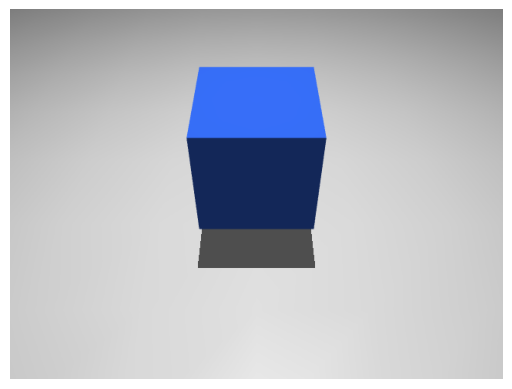

In [2]:
   import os
   # MuJoCo draws images using the GPU
   icd = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
   if not os.path.exists(icd):
       with open(icd, 'w') as f:
           f.write('{"file_format_version":"1.0.0","ICD":{"library_path":"libEGL_nvidia.so.0"}}')
   os.environ["MUJOCO_GL"] = "egl"

   import mujoco
   import matplotlib.pyplot as plt

   # A floor, a light and a blue box
   xml = """
   <mujoco>
     <worldbody>
       <light pos="0 0 3"/>
       <geom type="plane" size="2 2 0.1" rgba="0.8 0.8 0.8 1"/>
       <body pos="0 0 0.2">
         <freejoint/>
         <geom type="box" size="0.1 0.1 0.1" rgba="0.2 0.4 0.9 1"/>
       </body>
     </worldbody>
   </mujoco>
   """
   model = mujoco.MjModel.from_xml_string(xml)
   data = mujoco.MjData(model)
   mujoco.mj_forward(model, data)

   renderer = mujoco.Renderer(model, 480, 640)
   renderer.update_scene(data)
   plt.imshow(renderer.render())
   plt.axis("off")
   plt.show()